# Deep learning recommender

Author: Masha Khanina

Reviewer: 

Description: making movie recommendations system by using two-tower model for retrieval + mlp with early crossing for ranking recommendations.

Infinity Labs R&D AI #5

In [18]:
import copy
from collections import defaultdict
import random

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import ndcg_score
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from recommender_dl import build_mlp, move_tensors, train_val_split

In [19]:
with duckdb.connect("/home/maria-khanina/mkgit/movies_project/data/database.duckdb", read_only=True) as db_conn:
    ratings_df = db_conn.execute("""
        SELECT *
        FROM ratings
            INNER JOIN movies USING (movie_id)
            INNER JOIN users USING (user_id)
    """).df()

In [20]:
ratings_df.head()

,user_id,movie_id,rating,timestamp,title,genres,gender,age,occupation,zip_code
0,1945,1248,3,974692298,Touch of Evil (1958),Crime|Film-Noir|Thriller,M,25,20,92866
1,1945,1252,3,974691937,Chinatown (1974),Film-Noir|Mystery|Thriller,M,25,20,92866
2,1945,589,3,974692787,Terminator 2: Judgment Day (1991),Action|Sci-Fi|Thriller,M,25,20,92866
3,1945,6,3,974693183,Heat (1995),Action|Crime|Thriller,M,25,20,92866
4,1945,1267,2,974692090,"Manchurian Candidate, The (1962)",Film-Noir|Thriller,M,25,20,92866


In [21]:
ratings_df["age"].value_counts()

age
25    395556
35    199003
18    183536
45     83633
50     72490
56     38780
1      27211
Name: count, dtype: int64

In [22]:
genres_encoded = ratings_df["genres"].str.get_dummies(sep="|")
genres_cols = genres_encoded.columns.to_list()
genres_num = len(genres_cols)
ratings_df = pd.concat([ratings_df, genres_encoded], axis=1)

In [23]:
encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1,
)

cat_cols = ["gender"]

ratings_df[cat_cols] = encoder.fit_transform(ratings_df[cat_cols]) + 1
ratings_df["occupation"] = ratings_df["occupation"] + 1

In [24]:
max_user = int(ratings_df["user_id"].max())
max_movie = int(ratings_df["movie_id"].max())
max_age = int(ratings_df["age"].max())
max_gender = int(ratings_df["gender"].max())
max_job = int(ratings_df["occupation"].max())

In [25]:
class Ratings(Dataset):
    def __init__(
        self,
        df: pd.DataFrame,
        genres_cols: list[str],
        is_training=True,
        user_dropout=0.05,
    ) -> None:
        self.user_ids = torch.tensor(df["user_id"].values, dtype=torch.long)
        self.movie_ids = torch.tensor(df["movie_id"].values, dtype=torch.long)
        self.ages = torch.tensor(df["age"].values, dtype=torch.long)
        self.genders = torch.tensor(df["gender"].values, dtype=torch.long)
        self.jobs = torch.tensor(df["occupation"].values, dtype=torch.long)
        self.ratings = torch.tensor(df["normalized_rating"].values, dtype=torch.float32)
        self.genres = torch.tensor(df[genres_cols].values, dtype=torch.float32)
        self.is_training = is_training
        self.user_dropout = user_dropout

    def __len__(self) -> int:
        return len(self.user_ids)

    def __getitem__(self, idx: int) -> dict[str, torch.Tensor]:
        
        user_id = self.user_ids[idx]
        if self.is_training and random.random() < self.user_dropout:
            user_id = torch.tensor(0, dtype=torch.long)
            
        return {
            "user_id": user_id,
            "movie_id": self.movie_ids[idx],
            "age": self.ages[idx],
            "gender": self.genders[idx],
            "job": self.jobs[idx],
            "genres": self.genres[idx], 
            "rating": self.ratings[idx],
        }

In [26]:
class BaseRanker(nn.Module):
    def __init__(
        self,
        users_num: int,
        movies_num: int,
        add_interactions: bool = False,
        lin_layers_dims: list[int] = [128, 64, 32],
        dropout_ratio=0.2,
        user_dim=16,
        movie_dim=16,
        extra_input_dim=0,
    ) -> None:
        super().__init__()
        
        self.add_interactions = add_interactions
        
        self.user_embedding = nn.Embedding(
            num_embeddings=users_num + 1,
            embedding_dim=user_dim,
        )
        self.movie_embedding = nn.Embedding(
            num_embeddings=movies_num + 1,
            embedding_dim=movie_dim,
        )

        input_dim = user_dim + movie_dim + extra_input_dim
        
        if self.add_interactions:
            assert user_dim == movie_dim
            input_dim += user_dim

        self.mlp = build_mlp(
            input_dim=input_dim,
            hidden_dims=lin_layers_dims,
            output_dim=1,
            dropout_ratio=dropout_ratio,
        )

    def _get_base_features(
        self,
        user_ids: torch.Tensor,
        movie_ids: torch.Tensor,
    ) -> list[torch.Tensor]:
        user_vector = self.user_embedding(user_ids)
        movie_vector = self.movie_embedding(movie_ids)
        
        features = [user_vector, movie_vector]
        
        if self.add_interactions:
            features.append(user_vector * movie_vector)
            
        return features

    def forward(
        self,
        user_ids: torch.Tensor,
        movie_ids: torch.Tensor,
    ) -> torch.Tensor:
        
        features = self._get_base_features(user_ids, movie_ids)
        cat_features = torch.cat(features, dim=1)
        
        return self.mlp(cat_features).squeeze()


class RankerWithFeatures(BaseRanker):
    def __init__(
        self,
        users_num: int,
        movies_num: int,
        ages_num: int,
        genders_num: int,
        jobs_num: int,
        genres_num: int,
        add_interactions: bool = False,
        lin_layers_dims: list[int] = [128, 64, 32],
        dropout_ratio=0.2,
        user_dim=16,
        movie_dim=16,
        age_dim=3,
        gender_dim=2,
        job_dim=4,
        genre_dim=4,
    ) -> None:
        
        extra_dim = age_dim + gender_dim + job_dim + genre_dim

        super().__init__(
            users_num=users_num,
            movies_num=movies_num,
            add_interactions=add_interactions,
            lin_layers_dims=lin_layers_dims,
            dropout_ratio=dropout_ratio,
            user_dim=user_dim,
            movie_dim=movie_dim,
            extra_input_dim=extra_dim,
        )

        self.job_embedding = nn.Embedding(
            num_embeddings=jobs_num + 1,
            embedding_dim=job_dim,
        )
        self.age_embedding = nn.Embedding(
            num_embeddings=ages_num + 1,
            embedding_dim=age_dim,
        )
        self.gender_embedding = nn.Embedding(
            num_embeddings=genders_num + 1,
            embedding_dim=gender_dim,
        )
        self.genre_projector = nn.Linear(genres_num, genre_dim, bias=False)

    def forward(
        self,
        user_ids: torch.Tensor,
        movie_ids: torch.Tensor,
        ages: torch.Tensor,
        genders: torch.Tensor,
        jobs: torch.Tensor,
        genres: torch.Tensor,
    ) -> torch.Tensor:
        
        features = self._get_base_features(user_ids, movie_ids)
        
        features.extend([
            self.age_embedding(ages),
            self.gender_embedding(genders),
            self.job_embedding(jobs),
            self.genre_projector(genres),
        ])
        
        cat_features = torch.cat(features, dim=1)
        
        return self.mlp(cat_features).squeeze()

In [27]:
def _run_epoch(
    model: nn.Module,
    dataloader: DataLoader[dict[str, torch.Tensor]],
    var_key_map: dict[str, str],
    criterion: nn.Module,
    device: torch.device,
    is_train: bool,
    optimizer: optim.Optimizer | None = None,
) -> float:
    if is_train:
        model.train()
    else:
        model.eval()
    
    epoch_loss = 0.0
    dataset_len = 0
    
    with torch.set_grad_enabled(is_train):
        for batch in dataloader:
            feature_tensors = move_tensors(var_key_map, batch, device)

            y_true = batch["rating"].to(device).float()
            y_pred = model(**feature_tensors)
            
            loss = criterion(y_pred, y_true)
            
            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                
            epoch_loss += loss.item() * feature_tensors["user_ids"].size(0)
            dataset_len += feature_tensors["user_ids"].size(0)
            
    return epoch_loss / dataset_len


def train_ranker(
    model: nn.Module,
    train_loader: DataLoader[dict[str, torch.Tensor]],
    val_loader: DataLoader[dict[str, torch.Tensor]],
    var_key_map: dict[str, str],
    epochs=10_000,
    learning_rate=0.001,
    patience=10,
    tol=1e-4,
    weight_decay=1e-5,
) -> None:
    """if torch.cuda.is_available():
        device = torch.device("cuda")
    else:
        device = torch.device("cpu")"""
    device = torch.device("cpu")
    model = model.to(device)
    
    criterion = nn.MSELoss()
    optimizer = optim.AdamW(
        model.parameters(), 
        lr=learning_rate,
        weight_decay=weight_decay,
    )
    
    best_val_loss = np.inf
    to_beat_loss = np.inf
    no_improve_count = 0
    best_weights = None
    
    for epoch in range(epochs):
        avg_train_loss = _run_epoch(
            model=model,
            dataloader=train_loader,
            var_key_map=var_key_map,
            criterion=criterion,
            device=device,
            is_train=True,
            optimizer=optimizer,
        )
        
        avg_val_loss = _run_epoch(
            model=model,
            dataloader=val_loader,
            var_key_map=var_key_map,
            criterion=criterion,
            device=device,
            is_train=False,
        )
        
        print(
            f"Epoch {epoch+1}/{epochs}, "
            f"Train RMSE: {np.sqrt(avg_train_loss):.4f}, "
            f"Val RMSE: {np.sqrt(avg_val_loss):.4f}."
        )
        
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            best_weights = copy.deepcopy(model.state_dict())

        if avg_val_loss < (to_beat_loss - tol):
            to_beat_loss = avg_val_loss
            no_improve_count = 0
        else:
            no_improve_count += 1
            
        if no_improve_count >= patience:
            break
    
    if best_weights is not None:
        model.load_state_dict(best_weights)
        print(f"\nBest weights restored. Val RMSE: {np.sqrt(best_val_loss)}")

In [28]:
cold_user_ratio = 0.0

In [29]:
train_all_df, test_df = train_val_split(
    ratings_df,
    user_col="user_id",
    time_col="timestamp",
    cold_user_ratio=cold_user_ratio,
    max_test_ratio=0.1,
    test_max_per_var=8,
    test_min_per_var=3,
)

In [30]:
train_big_df, outer_val_df = train_val_split(
    train_all_df,
    user_col="user_id",
    time_col="timestamp",
    cold_user_ratio=cold_user_ratio,
    max_test_ratio=0.1,
    test_max_per_var=8,
    test_min_per_var=3,
)

In [31]:
train_df, val_df = train_val_split(
    train_big_df,
    user_col="user_id",
    time_col="timestamp",
    cold_user_ratio=cold_user_ratio,
    max_test_ratio=0.1,
    test_max_per_var=8,
    test_min_per_var=3,
)

In [32]:
rating_mean = train_df["rating"].mean()
users_rating_means = train_df.groupby("user_id")["rating"].mean()

for df in [train_df, val_df, outer_val_df, test_df]:
    df["user_mean"] = df["user_id"].map(users_rating_means).fillna(rating_mean)
    df["normalized_rating"] = df["rating"] - df["user_mean"]

In [33]:
var_key_map = {
    "user_ids": "user_id",
    "movie_ids": "movie_id",
    "ages": "age",
    "genders": "gender",
    "jobs": "job",
    "genres": "genres",
}

In [34]:
train_dataset = Ratings(
    train_df, 
    genres_cols, 
    is_training=True,
    user_dropout=cold_user_ratio
)
val_dataset = Ratings(val_df, genres_cols, is_training=False)

train_loader = DataLoader(
    train_dataset, 
    batch_size=1024, 
    shuffle=True,
    num_workers=4,
)

val_loader = DataLoader(
    val_dataset, 
    batch_size=1024, 
    shuffle=False,
    num_workers=4,
)

ranker_with_interactions = RankerWithFeatures(
    users_num=max_user,
    movies_num=max_movie,
    ages_num=max_age,
    genders_num=max_gender,
    jobs_num=max_job,
    genres_num=genres_num,
    add_interactions=True,
)

train_ranker(
    model=ranker_with_interactions,
    train_loader=train_loader,
    val_loader=val_loader,
    var_key_map=var_key_map,
    epochs=10_000,
    learning_rate=0.002,
)

Epoch 1/10000, Train RMSE: 0.9716, Val RMSE: 0.9684.
Epoch 2/10000, Train RMSE: 0.9260, Val RMSE: 0.9568.
Epoch 3/10000, Train RMSE: 0.9142, Val RMSE: 0.9504.
Epoch 4/10000, Train RMSE: 0.9013, Val RMSE: 0.9399.
Epoch 5/10000, Train RMSE: 0.8912, Val RMSE: 0.9331.
Epoch 6/10000, Train RMSE: 0.8843, Val RMSE: 0.9292.
Epoch 7/10000, Train RMSE: 0.8793, Val RMSE: 0.9266.
Epoch 8/10000, Train RMSE: 0.8753, Val RMSE: 0.9233.
Epoch 9/10000, Train RMSE: 0.8715, Val RMSE: 0.9225.
Epoch 10/10000, Train RMSE: 0.8679, Val RMSE: 0.9193.
Epoch 11/10000, Train RMSE: 0.8648, Val RMSE: 0.9182.
Epoch 12/10000, Train RMSE: 0.8615, Val RMSE: 0.9163.
Epoch 13/10000, Train RMSE: 0.8586, Val RMSE: 0.9164.
Epoch 14/10000, Train RMSE: 0.8556, Val RMSE: 0.9168.
Epoch 15/10000, Train RMSE: 0.8528, Val RMSE: 0.9169.
Epoch 16/10000, Train RMSE: 0.8501, Val RMSE: 0.9163.
Epoch 17/10000, Train RMSE: 0.8472, Val RMSE: 0.9162.
Epoch 18/10000, Train RMSE: 0.8449, Val RMSE: 0.9153.
Epoch 19/10000, Train RMSE: 0.8425, V

In [35]:
big_ranker_no_interactions = RankerWithFeatures(
    users_num=max_user,
    movies_num=max_movie,
    ages_num=max_age,
    genders_num=max_gender,
    jobs_num=max_job,
    genres_num=genres_num,
    add_interactions=False,
    dropout_ratio=0,
    user_dim=32,
    movie_dim=32,
    age_dim=4,
    gender_dim=1,
    job_dim=8,
    genre_dim=8,
)


train_ranker(
    model=big_ranker_no_interactions,
    train_loader=train_loader,
    val_loader=val_loader,
    var_key_map=var_key_map,
    epochs=10_000,
    learning_rate=0.002,
)

Epoch 1/10000, Train RMSE: 0.9512, Val RMSE: 0.9601.
Epoch 2/10000, Train RMSE: 0.9130, Val RMSE: 0.9494.
Epoch 3/10000, Train RMSE: 0.8939, Val RMSE: 0.9392.
Epoch 4/10000, Train RMSE: 0.8812, Val RMSE: 0.9300.
Epoch 5/10000, Train RMSE: 0.8725, Val RMSE: 0.9273.
Epoch 6/10000, Train RMSE: 0.8652, Val RMSE: 0.9259.
Epoch 7/10000, Train RMSE: 0.8582, Val RMSE: 0.9241.
Epoch 8/10000, Train RMSE: 0.8513, Val RMSE: 0.9257.
Epoch 9/10000, Train RMSE: 0.8445, Val RMSE: 0.9248.
Epoch 10/10000, Train RMSE: 0.8377, Val RMSE: 0.9241.
Epoch 11/10000, Train RMSE: 0.8310, Val RMSE: 0.9275.
Epoch 12/10000, Train RMSE: 0.8243, Val RMSE: 0.9295.
Epoch 13/10000, Train RMSE: 0.8178, Val RMSE: 0.9328.
Epoch 14/10000, Train RMSE: 0.8114, Val RMSE: 0.9336.
Epoch 15/10000, Train RMSE: 0.8051, Val RMSE: 0.9409.
Epoch 16/10000, Train RMSE: 0.7988, Val RMSE: 0.9412.
Epoch 17/10000, Train RMSE: 0.7929, Val RMSE: 0.9470.

Best weights restored. Val RMSE: 0.9240780692501905


In [36]:
ranker_no_interactions = RankerWithFeatures(
    users_num=max_user,
    movies_num=max_movie,
    ages_num=max_age,
    genders_num=max_gender,
    jobs_num=max_job,
    genres_num=genres_num,
    add_interactions=False,
)

In [37]:
train_ranker(
    model=ranker_no_interactions,
    train_loader=train_loader,
    val_loader=val_loader,
    var_key_map=var_key_map,
    epochs=10_000,
    learning_rate=0.002,
)

Epoch 1/10000, Train RMSE: 0.9678, Val RMSE: 0.9665.
Epoch 2/10000, Train RMSE: 0.9239, Val RMSE: 0.9565.
Epoch 3/10000, Train RMSE: 0.9090, Val RMSE: 0.9472.
Epoch 4/10000, Train RMSE: 0.8964, Val RMSE: 0.9372.
Epoch 5/10000, Train RMSE: 0.8878, Val RMSE: 0.9314.
Epoch 6/10000, Train RMSE: 0.8819, Val RMSE: 0.9265.
Epoch 7/10000, Train RMSE: 0.8774, Val RMSE: 0.9219.
Epoch 8/10000, Train RMSE: 0.8738, Val RMSE: 0.9200.
Epoch 9/10000, Train RMSE: 0.8701, Val RMSE: 0.9165.
Epoch 10/10000, Train RMSE: 0.8670, Val RMSE: 0.9159.
Epoch 11/10000, Train RMSE: 0.8641, Val RMSE: 0.9132.
Epoch 12/10000, Train RMSE: 0.8610, Val RMSE: 0.9140.
Epoch 13/10000, Train RMSE: 0.8585, Val RMSE: 0.9123.
Epoch 14/10000, Train RMSE: 0.8557, Val RMSE: 0.9112.
Epoch 15/10000, Train RMSE: 0.8535, Val RMSE: 0.9111.
Epoch 16/10000, Train RMSE: 0.8514, Val RMSE: 0.9080.
Epoch 17/10000, Train RMSE: 0.8493, Val RMSE: 0.9091.
Epoch 18/10000, Train RMSE: 0.8475, Val RMSE: 0.9088.
Epoch 19/10000, Train RMSE: 0.8454, V

In [38]:
base_ranker = BaseRanker(
    users_num=max_user,
    movies_num=max_movie,
)

train_ranker(
    model=base_ranker,
    train_loader=train_loader,
    val_loader=val_loader,
    var_key_map={
        "user_ids": "user_id", 
        "movie_ids": "movie_id",
    },
    epochs=10_000,
    learning_rate=0.002,
)

Epoch 1/10000, Train RMSE: 0.9694, Val RMSE: 0.9701.
Epoch 2/10000, Train RMSE: 0.9274, Val RMSE: 0.9613.
Epoch 3/10000, Train RMSE: 0.9171, Val RMSE: 0.9516.
Epoch 4/10000, Train RMSE: 0.9037, Val RMSE: 0.9401.
Epoch 5/10000, Train RMSE: 0.8937, Val RMSE: 0.9349.
Epoch 6/10000, Train RMSE: 0.8878, Val RMSE: 0.9305.
Epoch 7/10000, Train RMSE: 0.8836, Val RMSE: 0.9259.
Epoch 8/10000, Train RMSE: 0.8802, Val RMSE: 0.9250.
Epoch 9/10000, Train RMSE: 0.8777, Val RMSE: 0.9228.
Epoch 10/10000, Train RMSE: 0.8755, Val RMSE: 0.9213.
Epoch 11/10000, Train RMSE: 0.8734, Val RMSE: 0.9201.
Epoch 12/10000, Train RMSE: 0.8716, Val RMSE: 0.9201.
Epoch 13/10000, Train RMSE: 0.8700, Val RMSE: 0.9179.
Epoch 14/10000, Train RMSE: 0.8683, Val RMSE: 0.9191.
Epoch 15/10000, Train RMSE: 0.8667, Val RMSE: 0.9182.
Epoch 16/10000, Train RMSE: 0.8651, Val RMSE: 0.9192.
Epoch 17/10000, Train RMSE: 0.8640, Val RMSE: 0.9186.
Epoch 18/10000, Train RMSE: 0.8621, Val RMSE: 0.9193.
Epoch 19/10000, Train RMSE: 0.8609, V

In [39]:
outer_dataset = Ratings(outer_val_df, genres_cols, is_training=False)

outer_loader = DataLoader(
    outer_dataset, 
    batch_size=1024, 
    shuffle=False,
)


def report_per_user(
        model: nn.Module,
        dataloader: DataLoader[dict[str, torch.Tensor]],
        device: torch.device,
        var_key_map: dict[str, str],
) -> tuple[dict[int, list[float]], dict[int, list[float]]]:
    per_user_preds: dict[int, list[float]] = defaultdict(list)
    per_user_trues: dict[int, list[float]] = defaultdict(list)
    
    with torch.no_grad():
        for batch in dataloader:
            feature_tensors = move_tensors(var_key_map, batch, device)
                
            y_pred = model(**feature_tensors).cpu().numpy()
            y_true = batch["rating"].cpu().numpy()
            user_ids = batch["user_id"].cpu().numpy()
            
            for user_id, pred_value, true_value in zip(user_ids, y_pred, y_true):
                per_user_preds[user_id].append(pred_value)
                per_user_trues[user_id].append(true_value + 5.0)
    
    return per_user_preds, per_user_trues

def count_ndcg_per_user(
    per_user_preds: dict[int, list[float]],
    per_user_trues: dict[int, list[float]],
    recommend_num: int,
):
    ndcg_scores = []
    
    for user_id in per_user_preds:
        if len(per_user_preds[user_id]) > 1:
            user_true = np.array([per_user_trues[user_id]])
            user_pred = np.array([per_user_preds[user_id]])
            
            score = ndcg_score(user_true, user_pred, k=recommend_num)
            ndcg_scores.append(score)
    
    return ndcg_scores


def evaluate_mean_ndcg(
    model: nn.Module,
    dataloader: DataLoader[dict[str, torch.Tensor]],
    var_key_map: dict[str, str],
    device: torch.device,
    recommend_num: int = 5,
) -> float:
    model.eval()
    
    per_user_preds, per_user_trues = report_per_user(
        model, 
        dataloader, 
        device,
        var_key_map,
    )

    ndcg_scores = count_ndcg_per_user(
        per_user_preds,
        per_user_trues,
        recommend_num,
    )
            
    return np.mean(ndcg_scores) if ndcg_scores else 0.0


In [40]:
evaluate_mean_ndcg(
    ranker_no_interactions,
    outer_loader,
    var_key_map,
    torch.device("cpu"),
    recommend_num=5,
)

np.float64(0.9475469424743265)

In [41]:
from recommender_fm import count_baseline_score

count_baseline_score(
    train_df.drop(columns="rating"),
    outer_val_df.drop(columns="rating"),
    train_df["rating"],
    outer_val_df["rating"],
    recommend_num=5,
)

np.float64(0.849373442865673)

In [42]:
class PairwiseRatings(Dataset):
    def __init__(
        self,
        df: pd.DataFrame,
        genre_cols: list[str],
        is_training=True,
        user_dropout=0.05,
    ):
        self.is_training = is_training
        
        self.user_ids = torch.tensor(df["user_id"].values, dtype=torch.long)
        self.movie_ids = torch.tensor(df["movie_id"].values, dtype=torch.long)
        self.ages = torch.tensor(df["age"].values, dtype=torch.long)
        self.genders = torch.tensor(df["gender"].values, dtype=torch.long)
        self.jobs = torch.tensor(df["occupation"].values, dtype=torch.long)
        self.genres = torch.tensor(df[genre_cols].values, dtype=torch.float32)

        self.ratings = torch.tensor(df["rating"].values, dtype=torch.float32) 
        
        self.user_to_indices = df.groupby("user_id").indices
        self.user_dropout = user_dropout

    def __len__(self) -> int:
        return len(self.user_ids)

    def __getitem__(self, idx: int) -> dict[str, torch.Tensor]:
        user_id = self.user_ids[idx].item()
        
        user_indices = self.user_to_indices[user_id]
        idx2 = np.random.choice(user_indices)
        
        rating_1 = self.ratings[idx]
        rating_2 = self.ratings[idx2]
        
        if rating_1 >= rating_2:
            pos_idx, neg_idx = idx, idx2
        else:
            pos_idx, neg_idx = idx2, idx
            
        rating_diff = self.ratings[pos_idx] - self.ratings[neg_idx]
        
        user_tensor = torch.tensor(user_id, dtype=torch.long)
        if self.is_training and torch.rand(1).item() < self.user_dropout:
            user_tensor = torch.tensor(0, dtype=torch.long)
            
        return {
            "user_id": user_tensor,
            "age": self.ages[pos_idx],
            "gender": self.genders[pos_idx],
            "job": self.jobs[pos_idx],
            "pos_movie_id": self.movie_ids[pos_idx],
            "pos_genres": self.genres[pos_idx],
            "neg_movie_id": self.movie_ids[neg_idx],
            "neg_genres": self.genres[neg_idx],
            "rating_diff": rating_diff,
        }


def _run_pairwiise_epoch(
    model: nn.Module,
    dataloader: DataLoader[dict[str, torch.Tensor]],
    pos_key_map: dict[str, str],
    neg_key_map: dict[str, str],
    device: torch.device,
    is_train: bool,
    optimizer: optim.Optimizer | None = None,
) -> float:
    if is_train:
        model.train()
    else:
        model.eval()
    
    epoch_loss = 0.0
    dataset_len = 0
    
    with torch.set_grad_enabled(is_train):
        for batch in dataloader:
            pos_tensors = move_tensors(pos_key_map, batch, device)
            neg_tensors = move_tensors(neg_key_map, batch, device)
            rating_diff = batch["rating_diff"].to(device)

            combined_tensors = {}
            for model_var in pos_tensors:
                combined_tensors[model_var] = torch.cat(
                    [pos_tensors[model_var], neg_tensors[model_var]],
                    dim=0,
                )

            y_combined = model(**combined_tensors)
            y_pos, y_neg = torch.chunk(y_combined, 2, dim=0)
            
            base_loss = torch.relu(1.0 - (y_pos - y_neg))
            loss = torch.mean(rating_diff * base_loss)
            
            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                
            epoch_loss += loss.item() * rating_diff.size(0)
            dataset_len += rating_diff.size(0)
            
    return epoch_loss / dataset_len


def learn_to_rank(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    pos_key_map: dict[str, str],
    neg_key_map: dict[str, str],
    epochs=10_000,
    learning_rate=0.002,
    patience=10,
    tol=1e-4,
    weight_decay=1e-5,
    device_name: str = "cpu",
) -> None:
    
    device = torch.device(device_name)
    model = model.to(device)
    
    optimizer = optim.AdamW(
        model.parameters(), 
        lr=learning_rate,
        weight_decay=weight_decay,
    )
    
    best_val_loss = np.inf
    to_beat_loss = np.inf
    no_improve_count = 0
    best_weights = None
    
    for epoch in range(epochs):
        avg_train_loss = _run_pairwiise_epoch(
            model=model,
            dataloader=train_loader,
            pos_key_map=pos_key_map,
            neg_key_map=neg_key_map,
            device=device,
            is_train=True,
            optimizer=optimizer,
        )
        
        avg_val_loss = _run_pairwiise_epoch(
            model=model,
            dataloader=val_loader,
            pos_key_map=pos_key_map,
            neg_key_map=neg_key_map,
            device=device,
            is_train=False,
        )
        
        print(
            f"Epoch {epoch+1}/{epochs}, "
            f"Train Loss: {avg_train_loss:.4f}, "
            f"Val Loss: {avg_val_loss:.4f}."
        )
        
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            best_weights = copy.deepcopy(model.state_dict())

        if avg_val_loss < (to_beat_loss - tol):
            to_beat_loss = avg_val_loss
            no_improve_count = 0
        else:
            no_improve_count += 1
            
        if no_improve_count >= patience:
            break
    
    if best_weights is not None:
        model.load_state_dict(best_weights)
        print(
            "Best weights restored. "
            f"Validation loss is {best_val_loss:.4f}"
        )

In [43]:
pos_key_map = {
    "user_ids": "user_id", 
    "movie_ids": "pos_movie_id", 
    "ages": "age", 
    "genders": "gender", 
    "jobs": "job", 
    "genres": "pos_genres",
}

neg_key_map = {
    "user_ids": "user_id", 
    "movie_ids": "neg_movie_id",
    "ages": "age",
    "genders": "gender", 
    "jobs": "job", 
    "genres": "neg_genres",
}

In [44]:
train_dataset = PairwiseRatings(
    train_df, 
    genres_cols, 
    is_training=True,
    user_dropout=cold_user_ratio,
)
val_dataset = PairwiseRatings(val_df, genres_cols, is_training=False)
outer_dataset = PairwiseRatings(val_df, genres_cols, is_training=False)

train_loader = DataLoader(
    train_dataset, 
    batch_size=1024, 
    shuffle=True,
    num_workers=4,
    pin_memory=True,
)

val_loader = DataLoader(
    val_dataset, 
    batch_size=1024, 
    shuffle=False,
    num_workers=4,
    pin_memory=True,
)

In [ ]:
ranker_with_features = RankerWithFeatures(
    users_num=max_user,
    movies_num=max_movie,
    ages_num=max_age,
    genders_num=max_gender,
    jobs_num=max_job,
    genres_num=genres_num,
    add_interactions=False,
)

learn_to_rank(
    model=ranker_no_interactions,
    train_loader=train_loader,
    val_loader=val_loader,
    pos_key_map=pos_key_map,
    neg_key_map=neg_key_map,
    epochs=10_000,
    learning_rate=0.0005,
    weight_decay=1e-3,
)

/home/maria-khanina/mkgit/venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch 1/10000, Train Loss: 0.5344, Val Loss: 0.5622.
Epoch 2/10000, Train Loss: 0.5294, Val Loss: 0.5584.
Epoch 3/10000, Train Loss: 0.5267, Val Loss: 0.5541.
Epoch 4/10000, Train Loss: 0.5253, Val Loss: 0.5526.
Epoch 5/10000, Train Loss: 0.5249, Val Loss: 0.5571.
Epoch 6/10000, Train Loss: 0.5207, Val Loss: 0.5613.
Epoch 7/10000, Train Loss: 0.5188, Val Loss: 0.5581.
Epoch 8/10000, Train Loss: 0.5197, Val Loss: 0.5586.
Epoch 9/10000, Train Loss: 0.5193, Val Loss: 0.5608.


In [ ]:
evaluate_mean_ndcg(
    ranker_no_interactions,
    outer_loader,
    var_key_map,
    torch.device("cpu"),
    recommend_num=5,
)

np.float64(0.9451990847931803)

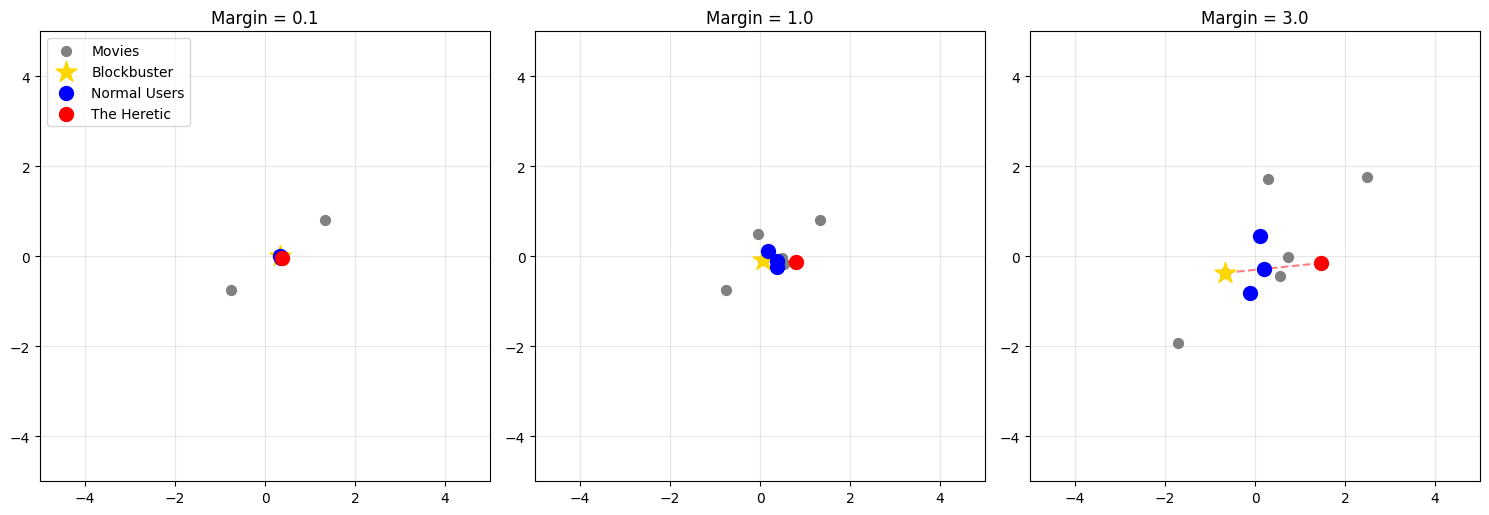

In [ ]:
def simulate_shared_items(
    margin: float, 
    epochs: int = 300,
):
    torch.manual_seed(42)
    
    users = torch.randn(4, 2, requires_grad=True)
    movies = torch.randn(6, 2, requires_grad=True)
    
    optimizer = optim.SGD([users, movies], lr=0.1)
    
    interactions = {
        0: ([0, 1, 2], [4]),
        1: ([0, 1, 3], [5]),
        2: ([0, 2], [3]),
        3: ([1, 2], [0]),
    }
    
    for _ in range(epochs):
        optimizer.zero_grad()
        total_loss = 0.0
        
        for user_idx, (likes, dislikes) in interactions.items():
            user_vector = users[user_idx : user_idx + 1]
            
            pos_vectors = movies[likes]
            dist_pos = torch.norm(user_vector - pos_vectors, dim=1)
            total_loss += torch.mean(dist_pos ** 2)
            
            neg_vectors = movies[dislikes]
            dist_neg = torch.norm(user_vector - neg_vectors, dim=1)
            loss_neg = torch.relu(margin - dist_neg) ** 2
            total_loss += torch.mean(loss_neg)
                
        total_loss.backward()
        optimizer.step()
        
    return users.detach().numpy(), movies.detach().numpy()


margins_to_test = [0.1, 1.0, 3.0]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for idx, margin in enumerate(margins_to_test):
    users, movies = simulate_shared_items(margin=margin)
    ax = axes[idx]
    
    ax.scatter(
        movies[:, 0], movies[:, 1], 
        color='gray', s=50, label='Movies', zorder=2,
    )
    ax.scatter(
        movies[0, 0], movies[0, 1], 
        color='gold', s=250, marker='*', label='Blockbuster', zorder=3,
    )
    ax.scatter(
        users[:3, 0], users[:3, 1], 
        color='blue', s=100, label='Normal Users', zorder=3,
    )
    ax.scatter(
        users[3, 0], users[3, 1], 
        color='red', s=100, label='The Heretic', zorder=3,
    )
    
    ax.plot(
        [users[3, 0], movies[0, 0]],
        [users[3, 1], movies[0, 1]], 
        'r--', alpha=0.5,
    )
    
    ax.set_title(f"Margin = {margin}")
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.grid(True, alpha=0.3)
    ax.set_aspect('equal', 'box')
    
    if idx == 0:
        ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

In [ ]:
train_df

NameError: name 'train_df' is not defined